# Investigating Glacial and Interglacial Cycles with Python
**GEOG 202 | Guided in-class investigation (~75–90 minutes)**

**Big question:** How has the Earth's climate changed in the past and how can we relate that to what we have learned this semester?

### **Learning goals:** 
1) read and plot climate data 
2) connect eccentricity, obliquity, and precession to seasonal insolation; 
3) interpret CO₂ and benthic δ¹⁸O records; 
4) compare ~41-kyr and ~100-kyr variability.

### **Instructions:** 
Run code cells in order with **Shift + Enter**. Code is provided; your job is to experiment and explain. Write answers in the markdown response cells or on the print out. 

### Helpful notes:
**ka** means thousands of years before present.

## Before you begin: data files
This notebook uses provided datasets. Check to see that you have the following files in the `data` folder.

- `INSOLN.LA2004.BTL.100.csv` — orbital parameters
- `j_65north.csv` — 65°N insolation
- `antarctica2015co2composite.txt` — Antarctic CO₂ composite
- `LR04stack.csv` — LR04 benthic oxygen-isotope stack

<font color=blue>**Tip:**</font> If a cell reports `FileNotFoundError`, check the `data` folder before continuing.

___ 

### Python basics and importing the scientific python packages we will need
Python is a popular general-purpose computer language. It is human readable and has many pre-built code toolboxes that can turn it into a fast platform for math, data analysis, and visualiztion. 

Today, we will not focus on how to code using Python, but instead look at ways we can use it to look at past climates. 

We will utilize several libraries to help us do this by running the `import` command flowed by the open source library. 

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
from scipy.interpolate import interp1d

___

## Spectral analysis

We will mainly focus on orbital cycles, but we're going to look at $\text{CO}_2$ data too. Both insolation and $\text{CO}_2$ have a lot of *wiggles* over the last million years, but are the wiggles related to each other?  One way to look at this is using **time series analysis** to answer the basic question: **Do the two data sets have wiggles with the same frequencies?**

The analysis boils down to this: 

- According to Fourier, any periodic function $f(t)$ can be represented as the sum of a series of sines and cosines:   

$$f(t)=a_0+ \sum_{k=1}^{\infty} \bigr[a_k    \cos  \bigr(  \frac{k \pi t}{L}  \bigr)  + b_k    \sin  \bigr( \frac{k \pi t}{L} \bigl) \bigl]  $$

Where $a_k$ and $b_k$ are the Fourier coefficients and control the amplitude of the sinusoidal wave, $-L$ to $L$ is the domain of the periodic function, $k$ is the index of the sinusoidal wave, and $\frac{k \pi}{L}$ gives the angular frequency of each wave. Each $k^{\text{th}}$-wave has a different amplitude and frequency, higher $k$ waves have higher frequency.

- You can represent data as a series in time (in the time-domain) as we have been doing OR you can represent the data in terms of frequency, looking for the **power** in the data as a function of frequency. Power is proportional to $\text{amplitude}^2$.  This is known as the **power spectrum**. 

Let us take advantage of a `signal.periodogram` function in the `scipy` package.  That module has functions that allow us to  calculate the **power spectral density** for a time series.  As a result we will be able to generate a **periodogram**, which is a plot of power versus frequency. 

We will also use a **window** in the periodogram calculation.  What a _window_ does is multiply the time series by a function (called a taper) that weights information, suppressing data at the edges of the window and focussing on the center of the window.  The simplest window is a **boxcar** which gives equal weight to everything inside the window.  In the following, we will use a **Hann window** which looks more like a bell curve. You can check it out here: https://en.wikipedia.org/wiki/Window_function

In [18]:
# run this cell to see the documentation for the periodogram function
signal.periodogram?

Signature:
signal.periodogram(
    x,
    fs=1.0,
    window='boxcar',
    nfft=None,
    detrend='constant',
    return_onesided=True,
    scaling='density',
    axis=-1,
)
Docstring:
Estimate power spectral density using a periodogram.

Parameters
----------
x : array_like
    Time series of measurement values
fs : float, optional
    Sampling frequency of the `x` time series. Defaults to 1.0.
window : str or tuple or array_like, optional
    Desired window to use. If `window` is a string or tuple, it is
    passed to `get_window` to generate the window values, which are
    DFT-even by default. See `get_window` for a list of windows and
    required parameters. If `window` is array_like it will be used
    directly as the window and its length must be equal to the length
    of the axis over which the periodogram is computed. Defaults
    to 'boxcar'.
nfft : int, optional
    Length of the FFT used. If `None` the length of `x` will be
    used.
detrend : str or function or `False`, 

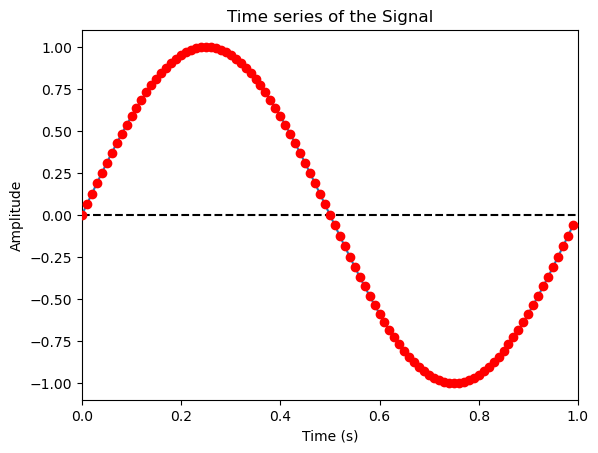

In [53]:
# period = 
# frequency = 

#Create time series of sine wave
target_freq=1  #Frequency of signal generated
fs = 100  # Sampling frequency in Hz # times per second
t = np.linspace(0, 1, fs, endpoint=False)  #Time series
sig = np.sin(2 * np.pi * target_freq * t) # y = sin(x)?
#+ np.random.normal(0, 0.1, fs)  #Amplitude of time series

#Plot time series of Sine wave
plt.plot(t, sig)


plt.scatter(t, sig, color='red', zorder=10)
plt.axhline(0, color='black', linestyle='--', zorder=0)
plt.xlim(0,1)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Time series of the Signal')
plt.show()

[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50.] [2.53377077e-36 5.00000000e-01 9.11218324e-36 4.90927324e-34
 9.19918279e-34 5.28101573e-34 5.80559320e-34 1.13100535e-33
 1.69091757e-34 2.06899694e-33 2.55408477e-33 1.26718668e-34
 1.12299645e-33 2.46936354e-35 1.36485734e-33 9.88004323e-35
 2.97527358e-34 3.03277539e-34 5.98382372e-34 4.18422393e-34
 8.90728318e-34 3.88607090e-34 3.36336997e-34 1.38911679e-35
 1.61791955e-33 2.98521487e-34 1.51261624e-33 1.49308455e-34
 4.28171151e-36 8.35928947e-34 5.15822939e-36 1.55658764e-34
 9.33613497e-35 1.71289354e-34 4.76777506e-34 2.70612791e-34
 3.59762396e-34 3.89795126e-34 3.40822711e-34 9.80860848e-34
 4.73198127e-35 4.57151461e-34 1.97346807e-35 4.99093771e-35
 2.10777057e-34 1.83302397e-34 3.00324455e-34 1.07950768e-33
 3.58802171e-34 1.13401171e-33 1.72145514e-33]


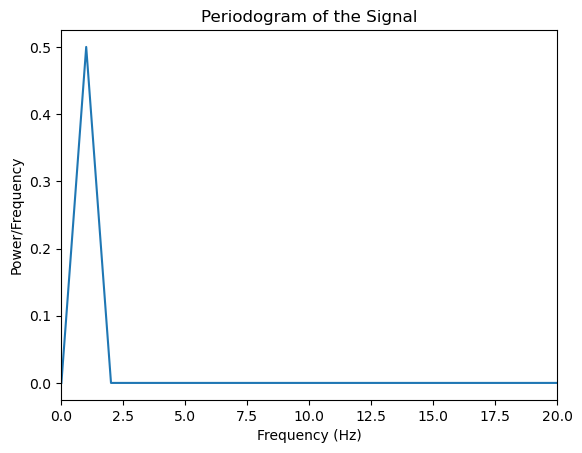

In [54]:
#Calculate spectrum frequencies and power
frequencies, power = signal.periodogram(sig, fs)  # sig = y, fs = sapling frequncy. 
print (frequencies,power)

#Plot the power (y) in each frequency (x)
plt.plot(frequencies, power)
plt.xlim(0,20)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency')
plt.title('Periodogram of the Signal')
plt.show()

In [55]:
np.argmax(power)

np.int64(1)

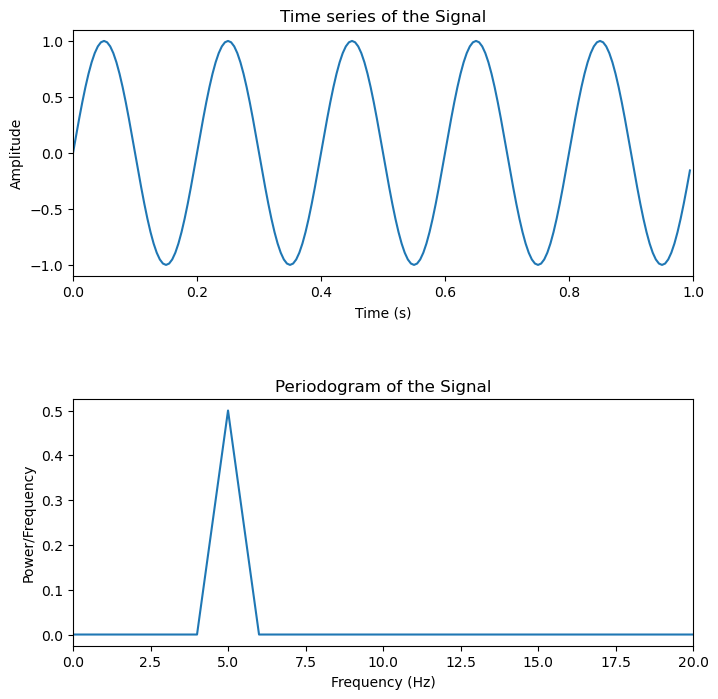

In [21]:
#Plot times series and spectrum
plt.figure(figsize=(8,8))
plt.subplots_adjust(hspace=0.5)

plt.subplot(2,1,1)
plt.plot(t, sig)
plt.xlim(0,1)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Time series of the Signal')

plt.subplot(2,1,2)
plt.plot(frequencies, power)
plt.xlim(0,20)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency')
plt.title('Periodogram of the Signal')
plt.show()

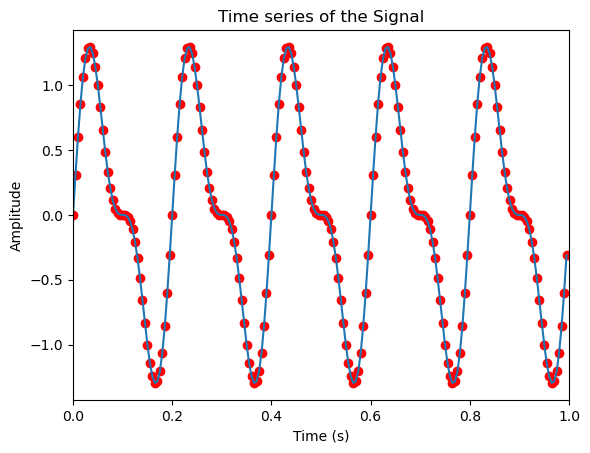

[  0.   1.   2.   3.   4.   5.   6.   7.   8.   9.  10.  11.  12.  13.
  14.  15.  16.  17.  18.  19.  20.  21.  22.  23.  24.  25.  26.  27.
  28.  29.  30.  31.  32.  33.  34.  35.  36.  37.  38.  39.  40.  41.
  42.  43.  44.  45.  46.  47.  48.  49.  50.  51.  52.  53.  54.  55.
  56.  57.  58.  59.  60.  61.  62.  63.  64.  65.  66.  67.  68.  69.
  70.  71.  72.  73.  74.  75.  76.  77.  78.  79.  80.  81.  82.  83.
  84.  85.  86.  87.  88.  89.  90.  91.  92.  93.  94.  95.  96.  97.
  98.  99. 100.] [2.62808391e-34 1.74855673e-32 1.38053208e-31 1.32280440e-31
 5.23712030e-34 5.00000000e-01 2.85070885e-32 1.15634453e-33
 9.73075413e-33 1.62096467e-32 1.25000000e-01 1.73583740e-32
 2.01044881e-32 4.29020250e-32 3.08510808e-33 6.54059228e-33
 5.10611337e-33 1.80210902e-32 4.07187070e-32 6.97510468e-33
 4.99719195e-32 2.57635226e-33 6.90216146e-33 1.45294052e-32
 2.25905485e-33 1.74747222e-32 6.11307602e-34 6.75713964e-33
 4.47221577e-33 1.32896533e-33 4.24005807e-33 1.42297708e-3

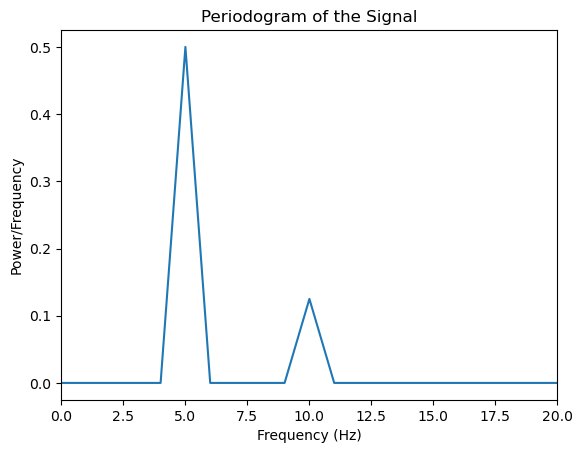

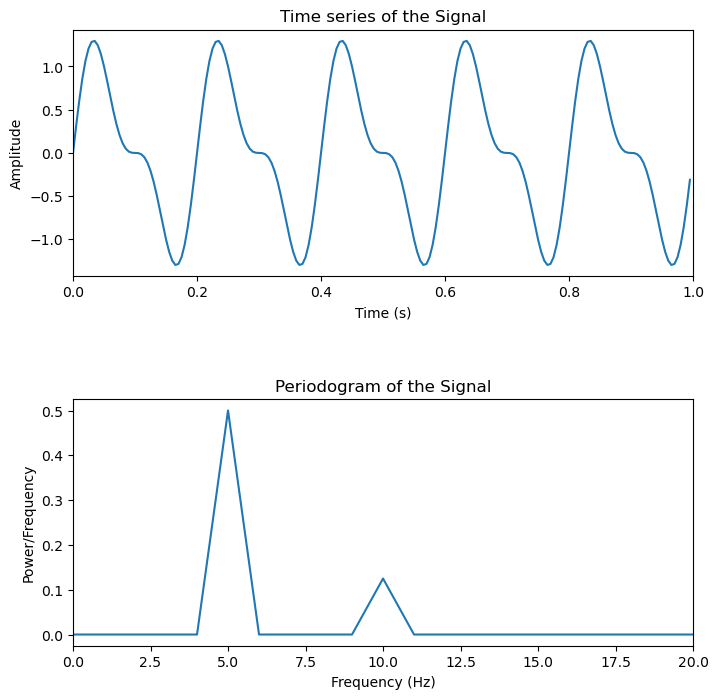

In [22]:
# period = 
# frequency = 

#Create time series of sine wave
target_freq=5  #Frequency of signal generated
fs = 200  # Sampling frequency in Hz
t = np.linspace(0, 1, fs, endpoint=False)  #Time series
sig = np.sin(2 * np.pi * target_freq * t) + 0.5*np.sin(2 * np.pi * (target_freq*2) * t) # y = sin(x)?
#+ np.random.normal(0, 0.1, fs)  #Amplitude of time series

#Plot time series of Sine wave
plt.plot(t, sig)
plt.scatter(t, sig, color='red')
plt.xlim(0,1)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Time series of the Signal')
plt.show()

#Calculate spectrum frequencies and power
frequencies, power = signal.periodogram(sig, fs)  # sig = y, fs = sapling frequncy. 
print (frequencies,power)

#Plot the power (y) in each frequency (x)
plt.plot(frequencies, power)
plt.xlim(0,20)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency')
plt.title('Periodogram of the Signal')
plt.show()

#Plot times series and spectrum
plt.figure(figsize=(8,8))
plt.subplots_adjust(hspace=0.5)

plt.subplot(2,1,1)
plt.plot(t, sig)
plt.xlim(0,1)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Time series of the Signal')

plt.subplot(2,1,2)
plt.plot(frequencies, power)
plt.xlim(0,20)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency')
plt.title('Periodogram of the Signal')
plt.show()


## Controls, feedbacks, and measures of climate

Apart from internal causes (like humans) Earth's climate is thought to be largely controlled by the amount of light from the sun arriving on Earth, called **insolation**.

This is controlled by the position of the Earth relative to the sun, referred to as the orbital parameters of **eccentricity**, **obliquity**, and **precession**.

As we know from more recent history, **$\text{CO}_2$** can warm and cool the Earth by trapping the incoming heat from the sun.

We can measure Earth's climate (in terms of **temperature**) back through time using various **climate proxies**. One of the best is $\delta$$O_{18}$.

<img src="./figures/Orbital-parameters-milankovitch_cycles.jpg" width = 1200>

## Investigating climate cycles
The Earth's orbital parameters of ellipticity, obliquity and precession vary in predictable ways.  One commonly used model for variations in them over the last few hundred million years was published by Laskar et al. (2004; http://dx.doi.org/10.1051/0004-6361:20041335).  

> This solution has been improved...by using a direct integration of the gravitational equations for the orbital motion, and by improving the dissipative contributions, in particular in the evolution of the Earth–Moon System. The orbital solution has been used for the calibration of the Neogene period (Lourens et al.  [CITE]), and is expected to be used for age calibrations of paleoclimatic data over 40 to 50 Myr, eventually over the full Palaeogene period (65 Myr) with caution. Beyond this time span, the chaotic evolution of the orbits prevents a precise determination of the Earth's motion. However, the most regular components of the orbital solution could still be used over a much longer time span. - Laskar et al. (2004)

Let's take a look for the behavior of the last few million years using the data file from the Laskar et al. (2004) paper. 

## Import the Lasker orbital solution

<font color=goldenrod>**Code for you to write**</font>
- Read in the data `INSOLN.LA2004.BTL.100.csv` and save it as `orbital_cycles`

In [23]:
orbital_cycles = pd.read_csv('data/INSOLN.LA2004.BTL.100.csv')
orbital_cycles.describe()

,Age (ka),Eccentricity,Obliquity,Precession
count,101001.000000,101001.000000,101001.000000,101001.000000
mean,50500.000000,0.027836,0.404392,3.140155
std,29156.621606,0.013255,0.008288,1.812224
min,0.000000,0.000106,0.382814,0.000039
25%,25250.000000,0.017686,0.397779,1.572261
50%,50500.000000,0.026889,0.404338,3.138744
75%,75750.000000,0.037304,0.410948,4.708932
max,101000.000000,0.066957,0.427330,6.283108


1. Age (ka)
   - Unit: ka stands for kilo-annum, meaning thousands of years before present (or relative to a specific model baseline).
   - Meaning: The time step of the row. For example, 0 is the present day, 1 is 1,000 years ago, 2 is 2,000 years ago, and so on.
   
2. Eccentricity
   - Unit: Dimensionless (no unit).
   - Meaning: Measures how much Earth's orbit around the Sun deviates from a perfect circle. A value of 0 is a perfect circle, while higher values mean a more elliptical (oval) orbit. The values hover around 0.016, which matches Earth's current low-eccentricity orbit.   

3. Obliquity
   - Unit: Radians (specifically, roughly 0.409 radians corresponds to Earth's axial tilt of about $23.44^\circ$).   
   - Meaning: Represents Earth's axial tilt relative to its orbital plane. It dictates the intensity of the seasons and fluctuates between roughly 0.386 and 0.427 radians ($22.1^\circ$ to $24.5^\circ$) over a 41,000-year cycle. 

<font color=goldenrod>**Code for you to write**</font>

Define a variable called `orbital_cycles_1Myr` that is masked to only have data for the past 1 million years (1000 ka).

In [24]:
#Filter the dataset to only the past 1000 ka
orbital_cycles_1Myr = orbital_cycles[orbital_cycles['Age (ka)']<=5225]
orbital_cycles_1Myr.describe()

,Age (ka),Eccentricity,Obliquity,Precession
count,5226.000000,5226.000000,5226.000000,5226.000000
mean,2612.500000,0.027775,0.406232,3.131023
std,1508.760584,0.013123,0.009079,1.813890
min,0.000000,0.000246,0.384696,0.000311
25%,1306.250000,0.017865,0.398815,1.560845
50%,2612.500000,0.027712,0.406242,3.128156
75%,3918.750000,0.036946,0.413589,4.695790
max,5225.000000,0.057815,0.426991,6.283068


Because the time is time before present (i.e. age), plot the older time on the left and the present day on the right by using `xlim(larger_number,smaller_number)`

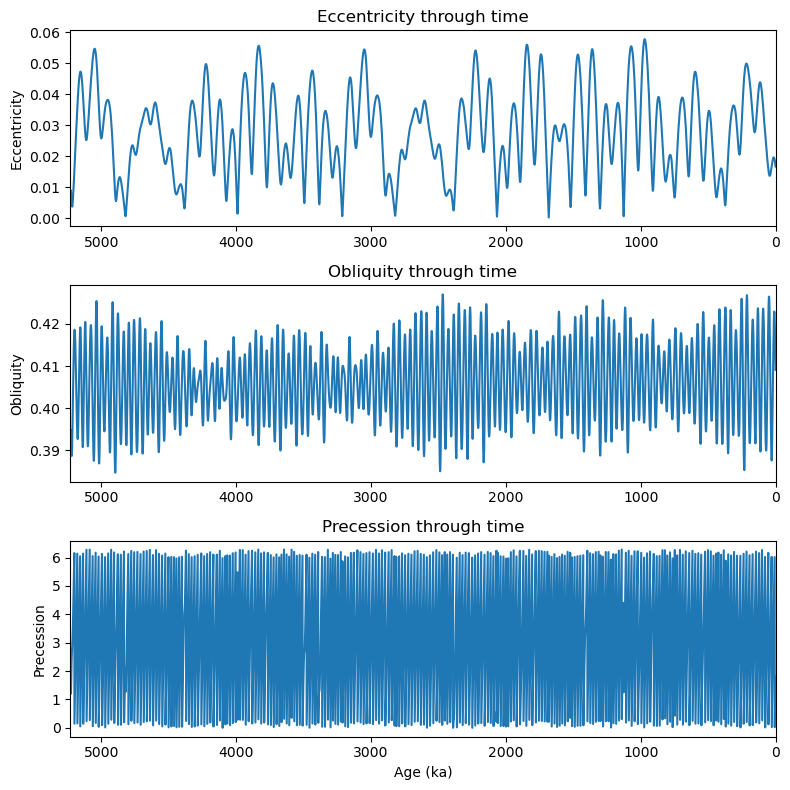

In [25]:
plt.figure(figsize=(8,8))

plt.subplot(3,1,1)
plt.plot(orbital_cycles_1Myr['Age (ka)'],orbital_cycles_1Myr['Eccentricity'])
plt.xlim(5230,0)
plt.ylabel('Eccentricity')
plt.title('Eccentricity through time')

plt.subplot(3,1,2)
plt.plot(orbital_cycles_1Myr['Age (ka)'],orbital_cycles_1Myr['Obliquity'])
plt.xlim(5230,0)
plt.ylabel('Obliquity')
plt.title('Obliquity through time')

plt.subplot(3,1,3)
plt.plot(orbital_cycles_1Myr['Age (ka)'],orbital_cycles_1Myr['Precession'])
plt.xlim(5230,0)
plt.ylabel('Precession')
plt.xlabel('Age (ka)')
plt.title('Precession through time')
plt.tight_layout()
plt.show()

Let's investigate the periodicity of these signals.

<font color=goldenrod>**Code for you to write**</font>
- Use `signal.periodogram` to calculate the frequencies and powers for the `Eccentricity` series
- Use `signal.periodogram` to calculate the frequencies and powers for the `Obliquity` series
- Use `signal.periodogram` to calculate the frequencies and powers for the `Precession` series
- As three subplots, plot the spectra for each of the Eccentricity, Obliquity, and Precession
- Add x and y labels and a title

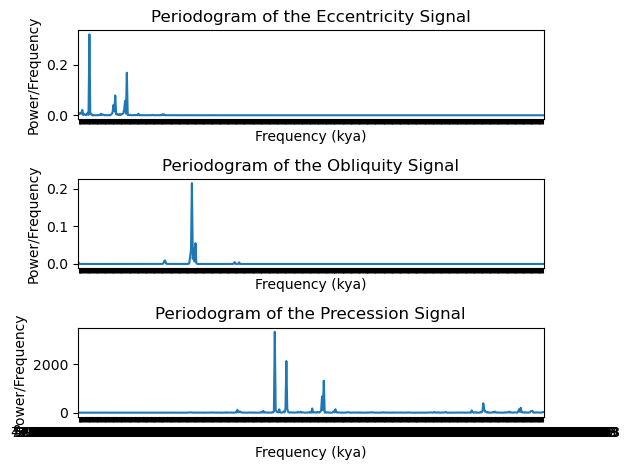

In [66]:
#Save the frequencies and power in the insolation time series to new variables
frequency_ecc, power_ecc = signal.periodogram(orbital_cycles_1Myr['Eccentricity'], 1)
frequency_obl, power_obl = signal.periodogram(orbital_cycles_1Myr['Obliquity'], 1)
frequency_prec, power_prec = signal.periodogram(orbital_cycles_1Myr['Precession'], 1)

#Plot the power (y) in each frequency (x)
#Plot times series and spectrum

fig, axes = plt.subplots(3,1, sharex=True)

labels = ['Eccentricity', 'Obliquity', 'Precession']
frequencies = [frequency_ecc, frequency_obl, frequency_prec]
powers = [power_ecc, power_obl, power_prec]

# # converting to frequncy of years
# tick_pos = np.arange(1990, 1991.2, .2)
# tick_label = ['Jan', 'March', 'April', 'July', 'Sept', 'Oct', 'Dec']
# plt.xticks(tick_pos, tick_label)

for i, ax in enumerate(axes):
    axes[i].plot(frequencies[i], powers[i])
    axes[i].set_xlabel('Frequency (kya)')
    axes[i].set_ylabel('Power/Frequency')
    axes[i].set_title(f'Periodogram of the {labels[i]} Signal')


xticks = frequencies[i][1:]
xlabels = 1/frequencies[1][1:]
plt.xticks(xticks, xlabels)
plt.xlim(0,0.1)
plt.tight_layout()
plt.show()

In [67]:
xticks

array([1.91350938e-04, 3.82701875e-04, 5.74052813e-04, ...,
       4.99617298e-01, 4.99808649e-01, 5.00000000e-01], shape=(2613,))

In [27]:
1/0.025

40.0

## Relating these cycles to incoming insolation

You can see a lot of cycles on different time scales. The question is how this relates to the **amount of insolation, i.e. the amount of solar energy arriving on Earth**.  In the literature, there are many attempts to convert the orbital parameters, like those in the plot above, to the amount of insolation received by the Earth's atmosphere as a function of latitude and age. You can get such estimates here: https://www.ncdc.noaa.gov/paleo-search/study/5792 associated with this paper (Huybers, P. 2006, http://www.sciencemag.org/cgi/content/full/313/5786/508).  

It is traditional to consider the amount of insolation received at 65&deg;N.  So let's take a look.

<font color=goldenrod>**Code for you to write**</font>
- Read in the data `j_65north.csv`
- Save this as the dataframe `insolation`
- Take a look at the dataframe using the usual tools

In [28]:
insolation = pd.read_csv('data/j_65north.csv')
insolation.head()

,Age (ka),Insolation (GJ/m^2)
0,0,6.763
1,1,6.776
2,2,6.788
3,3,6.799
4,4,6.810


<font color=goldenrod>**Code for you to write**</font>
- Plot insolation as a line graph
- Using `xlim` plot the time from 1000 ka to 0 ka (1,000 thousand years ago [same as 1 million] to present-day), putting the older date on the left and the present day on the right.
- Add x and y labels and a title

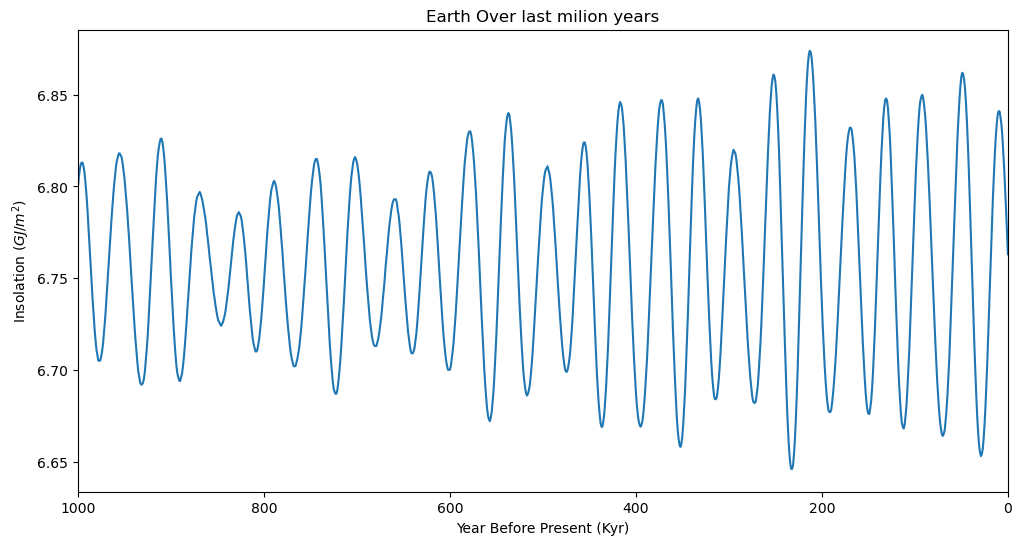

In [29]:


#Plot insolation versus time
plt.figure(figsize=(12,6))
plt.plot(insolation['Age (ka)'], insolation['Insolation (GJ/m^2)'])
plt.xlim(1000, insolation['Age (ka)'].min())
plt.title('Earth Over last milion years')
plt.ylabel(f'Insolation ($GJ/m^2$)')
plt.xlabel('Year Before Present (Kyr)')
plt.show()

## How big are these insolation changes?

These changes in insolation are interpretted to be important in driving glacial-interglacial cycles. How big are the changes in insolation?

<font color=goldenrod>**Code for you to write**</font>

- Calculate the mean, minimum, and maximum insolation from the data.
- Use these values to calculate the percentage difference between the minumum insolation and the mean. Do the same between the maximum and the mean.

The percentage difference is calculated as the difference from the mean, divided by the mean
e.g $\frac{max(a)-mean(a)}{mean(a)}$



In [30]:
#Find the mean, minimum, and maximum insolation
insolation['Insolation (GJ/m^2)'].describe()

count    5001.000000
mean        6.755871
std         0.048433
min         6.645000
25%         6.717000
50%         6.755000
75%         6.794000
max         6.874000
Name: Insolation (GJ/m^2), dtype: float64

In [31]:
#Calculate the percentage difference between the maximum and the mean insolation
((insolation['Insolation (GJ/m^2)'].describe()['max'] - insolation['Insolation (GJ/m^2)'].describe()['mean'])/insolation['Insolation (GJ/m^2)'].describe()['mean'])*100

np.float64(1.7485380309086151)

In [32]:
#Calculate the percentage difference between the minimum and the mean insolation
((insolation['Insolation (GJ/m^2)'].describe()['min'] - insolation['Insolation (GJ/m^2)'].describe()['mean'])/insolation['Insolation (GJ/m^2)'].describe()['mean'])*100

np.float64(-1.6411063114070792)

<font color=red>**Discussion question:**</font> Does this change seem like a big change sufficient to drive these cycles?

If no, then we're missing something. This something is the feedback.

## What is the dominant periodic signal in the insolation curve?


<font color=goldenrod>**Code for you to write**</font>
- Use `signal.periodgram` to calculate and plot the frequencies and power for the `Insolation (W/m^2)` series
- Add x and y labels and a title

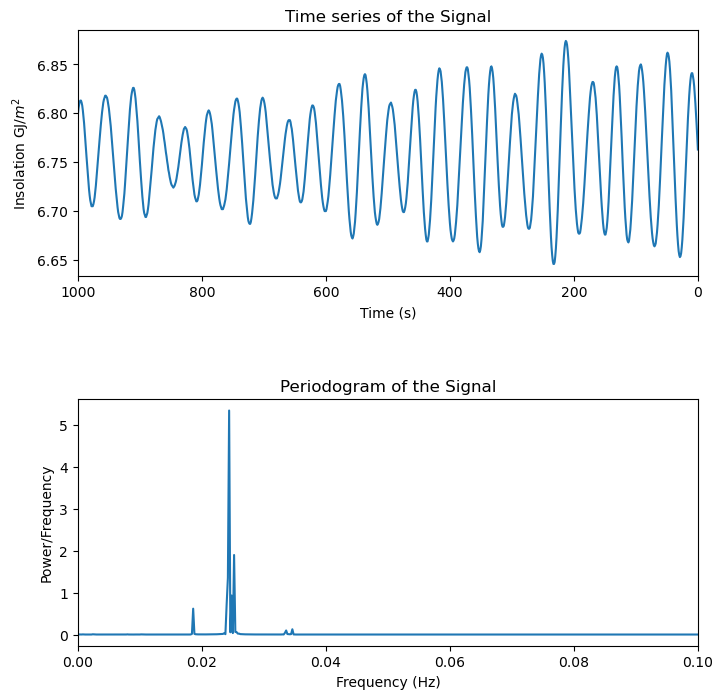

In [33]:
#Save the frequencies and power in the insolation time series to new variables
frequency_insol, power_insol = signal.periodogram(insolation['Insolation (GJ/m^2)'], 1)

#Plot the power (y) in each frequency (x)
#Plot times series and spectrum
plt.figure(figsize=(8,8))
plt.subplots_adjust(hspace=0.5)

plt.subplot(2,1,1)
plt.plot(insolation['Age (ka)'], insolation['Insolation (GJ/m^2)'])
plt.xlabel('Time (s)')
plt.ylabel('Insolation GJ/$m^2$')
plt.xlim(1000,0)
plt.title('Time series of the Signal')

plt.subplot(2,1,2)
plt.plot(frequency_insol, power_insol)

plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency')
plt.title('Periodogram of the Signal')
plt.xlim(0,0.1)
plt.show()

In [34]:
np.argmax(frequency_insol)

np.int64(2500)

## What does this dominant peak correspond to?

We know that eccentricity is supposed to have a dominant period at 100 kyr, obliquity at 41 kyr and precession at 23 and 19 kyr. Remember that these numbers are expressed in terms of the period. 

<font color=goldenrod>**Code for you to write**</font>

Convert the periods of the eccentricity, obliquity, and precessions 1 and 2 to frequency. **Period is the inverse of the frequency.**

In [35]:
eccentricity_frequency = 1/100 #1/np.max(frequency_insol)
obliquity_frequency = 1/41 #1/np.max(frequency_obl)
precession_frequency_1 = 1/22.1 
precession_frequency_2 = 1/19

Because the amplitudes of the different peaks are so large we're going to plot these on a **log axis** using `plt.semilogy`.

In [36]:
plt.semilogy?

Signature: plt.semilogy(*args, **kwargs) -> 'list[Line2D]'
Docstring:
Make a plot with log scaling on the y-axis.

Call signatures::

    semilogy([x], y, [fmt], data=None, **kwargs)
    semilogy([x], y, [fmt], [x2], y2, [fmt2], ..., **kwargs)

This is just a thin wrapper around `.plot` which additionally changes
the y-axis to log scaling. All the concepts and parameters of plot can
be used here as well.

The additional parameters *base*, *subs*, and *nonpositive* control the
y-axis properties. They are just forwarded to `.Axes.set_yscale`.

Parameters
----------
base : float, default: 10
    Base of the y logarithm.

subs : array-like, optional
    The location of the minor yticks. If *None*, reasonable locations
    are automatically chosen depending on the number of decades in the
    plot. See `.Axes.set_yscale` for details.

nonpositive : {'mask', 'clip'}, default: 'clip'
    Non-positive values in y can be masked as invalid, or clipped to a
    very small positive number.

**kwar

We want to match the observed frequencies with what we know. We can use `axvline` to plot a vertical line at the frequencies of the orbital parameters.

In [37]:
plt.axvline?

Signature: plt.axvline(x: 'float' = 0, ymin: 'float' = 0, ymax: 'float' = 1, **kwargs) -> 'Line2D'
Docstring:
Add a vertical line spanning the whole or fraction of the Axes.

Note: If you want to set y-limits in data coordinates, use
`~.Axes.vlines` instead.

Parameters
----------
x : float, default: 0
    x position in :ref:`data coordinates <coordinate-systems>`.

ymin : float, default: 0
    The start y-position in :ref:`axes coordinates <coordinate-systems>`.
    Should be between 0 and 1, 0 being the bottom of the plot, 1 the
    top of the plot.

ymax : float, default: 1
    The end y-position in :ref:`axes coordinates <coordinate-systems>`.
    Should be between 0 and 1, 0 being the bottom of the plot, 1 the
    top of the plot.

Returns
-------
`~matplotlib.lines.Line2D`
    A `.Line2D` specified via two points ``(x, ymin)``, ``(x, ymax)``.
    Its transform is set such that *x* is in
    :ref:`data coordinates <coordinate-systems>` and *y* is in
    :ref:`axes coordinates <coo

We can plot these on our spectra of the orbital parameters

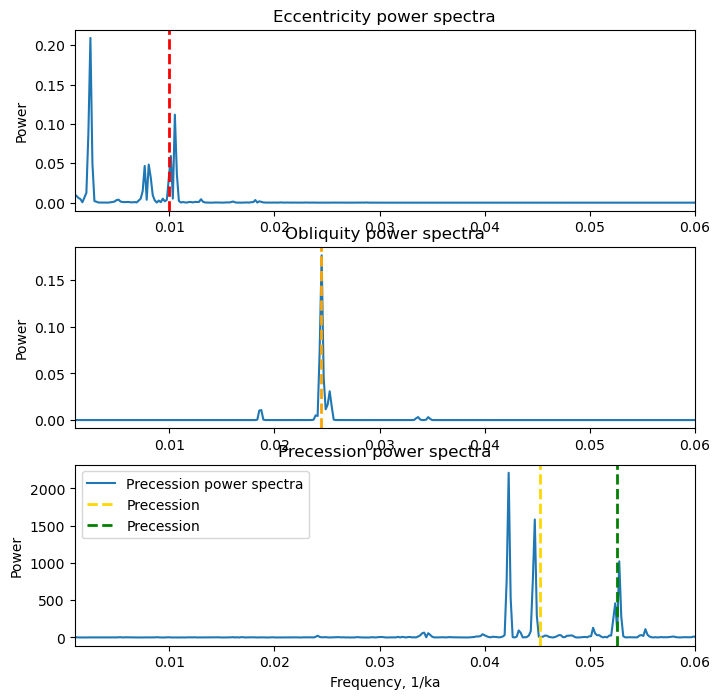

0.01
0.024390243902439025
0.04524886877828054
0.05263157894736842


In [38]:
#Save the frequencies and power in the insolation time series to new variables
eccentricity_freqs,eccentricity_power = signal.periodogram(orbital_cycles_1Myr['Eccentricity'],window='hann')
obliquity_freqs,obliquity_power = signal.periodogram(orbital_cycles_1Myr['Obliquity'],window='hann')
precession_freqs,precession_power = signal.periodogram(orbital_cycles_1Myr['Precession'],window='hann')

plt.figure(figsize=(8,8))

plt.subplot(3,1,1)
plt.plot(eccentricity_freqs,eccentricity_power,label='Eccentricity power spectra')
plt.axvline(x=eccentricity_frequency,color='red',label='Eccentricity',linewidth=2,linestyle='--') 
plt.xlim(.001,.06)
plt.ylabel('Power') 
plt.title('Eccentricity power spectra')

plt.subplot(3,1,2)
plt.plot(obliquity_freqs,obliquity_power,label='Obliquity power spectra')
plt.axvline(x=obliquity_frequency,color='orange',label='Obliquity',linewidth=2,linestyle='--')
plt.xlim(.001,.06)
plt.ylabel('Power') 
plt.title('Obliquity power spectra')

plt.subplot(3,1,3)
plt.plot(precession_freqs,precession_power,label='Precession power spectra')
plt.axvline(x=precession_frequency_1,color='gold',label='Precession',linewidth=2,linestyle='--') 
plt.axvline(x=precession_frequency_2,color='green',label='Precession',linewidth=2,linestyle='--') 
plt.xlim(.001,.06)
plt.xlabel('Frequency, 1/ka')
plt.ylabel('Power') 
plt.title('Precession power spectra')
plt.legend()
plt.show()


print(eccentricity_frequency) 
print(obliquity_frequency)
print(precession_frequency_1)
print(precession_frequency_2)

<font color=red>**Question**</font> Do these lines match the data perfectly? **If not, adjust the frequencies defined above to make them match.** Are the discrepancies large?

Now let's apply this to the insolation data

<font color=goldenrod>**Code for you to write**</font>
- Plot the insolation frequncies and power using `semilogy`
- Use `plt.axvline` to add four vertical lines at the frequencies of `eccentricity_frequency`, `obliquity_frequency`, `precession_frequency_1`, and `precession_frequency_2`
- Give them labels
- Give them different colours

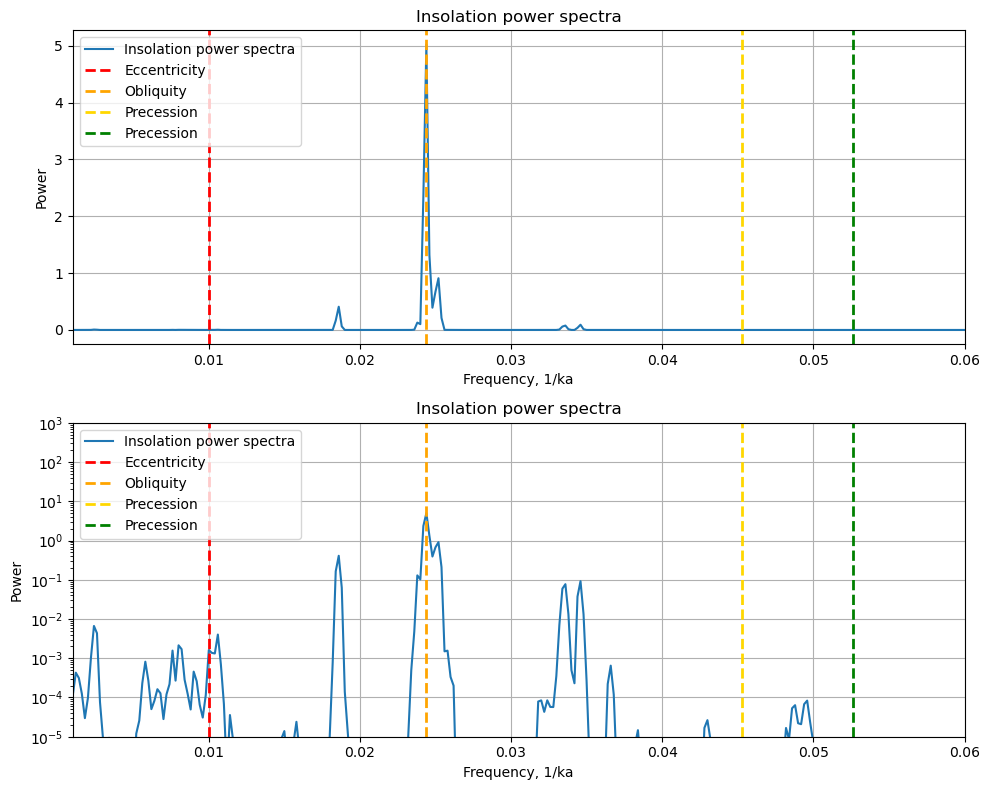

In [40]:
insolation_freqs,insolation_power = signal.periodogram(insolation['Insolation (GJ/m^2)'],window='hann')

plt.figure(figsize=(10,8))
plt.subplot(2,1,1)
plt.plot(insolation_freqs,insolation_power,label='Insolation power spectra')
plt.axvline(x=eccentricity_frequency,color='red',label='Eccentricity',linewidth=2,linestyle='--') 
plt.axvline(x=obliquity_frequency,color='orange',label='Obliquity',linewidth=2,linestyle='--')
plt.axvline(x=precession_frequency_1,color='gold',label='Precession',linewidth=2,linestyle='--') 
plt.axvline(x=precession_frequency_2,color='green',label='Precession',linewidth=2,linestyle='--') 
plt.xlim(.001,.06)
plt.xlabel('Frequency, 1/ka')
plt.ylabel('Power') 
plt.title('Insolation power spectra')
plt.legend()
plt.grid()

plt.subplot(2,1,2)
plt.semilogy(insolation_freqs,insolation_power,label='Insolation power spectra')
plt.axvline(x=eccentricity_frequency,color='red',label='Eccentricity',linewidth=2,linestyle='--') 
plt.axvline(x=obliquity_frequency,color='orange',label='Obliquity',linewidth=2,linestyle='--')
plt.axvline(x=precession_frequency_1,color='gold',label='Precession',linewidth=2,linestyle='--') 
plt.axvline(x=precession_frequency_2,color='green',label='Precession',linewidth=2,linestyle='--') 
plt.xlim(.001,.06)
plt.ylim(10e-6,10e2)
plt.xlabel('Frequency, 1/ka')
plt.ylabel('Power') 
plt.title('Insolation power spectra')
plt.legend()
plt.tight_layout()
plt.grid()
plt.show()

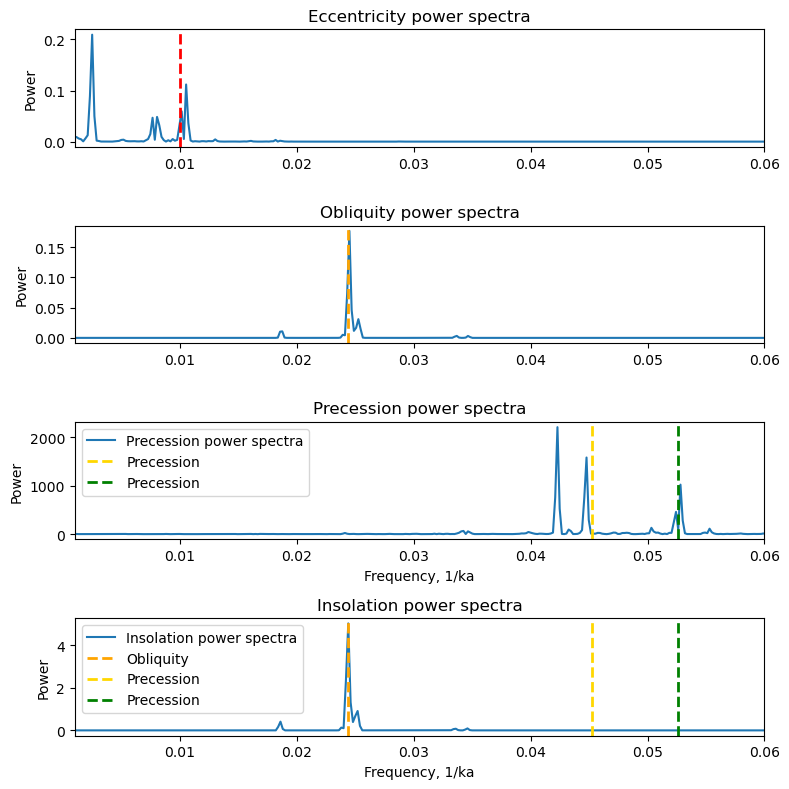

In [62]:
eccentricity_freqs,eccentricity_power = signal.periodogram(orbital_cycles_1Myr['Eccentricity'],window='hann')
obliquity_freqs,obliquity_power = signal.periodogram(orbital_cycles_1Myr['Obliquity'],window='hann')
precession_freqs,precession_power = signal.periodogram(orbital_cycles_1Myr['Precession'],window='hann')
insolation_freqs,insolation_power = signal.periodogram(insolation['Insolation (GJ/m^2)'],window='hann')

plt.figure(figsize=(8,8))

plt.subplot(4,1,1)
plt.plot(eccentricity_freqs,eccentricity_power,label='Eccentricity power spectra')
plt.axvline(x=eccentricity_frequency,color='red',label='Eccentricity',linewidth=2,linestyle='--') 
plt.xlim(.001,.06)
plt.ylabel('Power') 
plt.title('Eccentricity power spectra')

plt.subplot(4,1,2)
plt.plot(obliquity_freqs,obliquity_power,label='Obliquity power spectra')
plt.axvline(x=obliquity_frequency,color='orange',label='Obliquity',linewidth=2,linestyle='--')
plt.xlim(.001,.06)
plt.ylabel('Power') 
plt.title('Obliquity power spectra')

plt.subplot(4,1,3)
plt.plot(precession_freqs,precession_power,label='Precession power spectra')
plt.axvline(x=precession_frequency_1,color='gold',label='Precession',linewidth=2,linestyle='--') 
plt.axvline(x=precession_frequency_2,color='green',label='Precession',linewidth=2,linestyle='--') 
plt.xlim(.001,.06)
plt.xlabel('Frequency, 1/ka')
plt.ylabel('Power') 
plt.title('Precession power spectra')
plt.legend()

plt.subplot(4,1,4)
plt.plot(insolation_freqs,insolation_power,label='Insolation power spectra')
# plt.axvline(x=eccentricity_frequency,color='red',label='Eccentricity',linewidth=2,linestyle='--') 
plt.axvline(x=obliquity_frequency,color='orange',label='Obliquity',linewidth=2,linestyle='--')
plt.axvline(x=precession_frequency_1,color='gold',label='Precession',linewidth=2,linestyle='--') 
plt.axvline(x=precession_frequency_2,color='green',label='Precession',linewidth=2,linestyle='--') 
plt.xlim(.001,.06)
plt.xlabel('Frequency, 1/ka')
plt.ylabel('Power') 
plt.title('Insolation power spectra')
plt.legend()

plt.tight_layout()
plt.show()

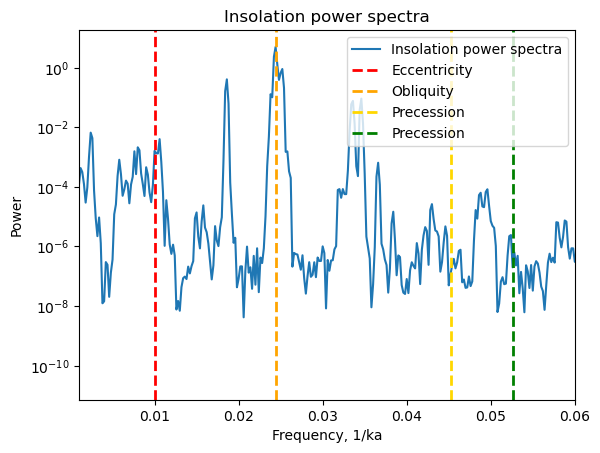

In [65]:
plt.semilogy(insolation_freqs,insolation_power,label='Insolation power spectra')
plt.axvline(x=eccentricity_frequency,color='red',label='Eccentricity',linewidth=2,linestyle='--') 
plt.axvline(x=obliquity_frequency,color='orange',label='Obliquity',linewidth=2,linestyle='--')
plt.axvline(x=precession_frequency_1,color='gold',label='Precession',linewidth=2,linestyle='--') 
plt.axvline(x=precession_frequency_2,color='green',label='Precession',linewidth=2,linestyle='--') 
plt.xlim(.001,.06)
plt.xlabel('Frequency, 1/ka')
plt.ylabel('Power') 
plt.title('Insolation power spectra')
plt.legend()

In [59]:
T = 1/np.argmax(insolation_power)
print(f'The period of the insolation signal is {T} ka, which is approximately 100 ka, which is the period of the eccentricity cycle.')

The period of the insolation signal is 0.00819672131147541 ka, which is approximately 100 ka, which is the period of the eccentricity cycle.


## Let's have a look at the ice core $\text{CO}_2$ data. Does the signal match with the insolation signal?

<font color=goldenrod>**Code for you to write**</font>

Read in the csv file from `./data/antarctica2015co2composite.txt` into the dataframe `ice_core_co2`:
- use the `skiprows` argument to remove the 137 header lines
- use the `sep` argument to set tab separated with '\t'
- create a new series in the `ice_core_co2` called `age_ka` by dividing the series `age_gas_calBP` by 1000 to convert from years to thousands of years
- take a look at the data using the usual tools

In [ ]:
#Read in data and create new series in thousands of years, then display dataframe to screen
ice_core_co2 = pd.read_csv('data/antarctica2015co2composite.txt', sep='\t',skiprows=137)
ice_core_co2['age_ka']=ice_core_co2['age_gas_calBP']/1000
ice_core_co2.tail()

,age_gas_calBP,co2_ppm,co2_1s_ppm,age_ka
1896,803925.28,202.92,2.06,803.92528
1897,804009.87,207.50,0.92,804.00987
1898,804522.67,204.86,1.64,804.52267
1899,805132.44,202.23,0.69,805.13244
1900,805668.87,207.29,2.20,805.66887


Let's visualise the data.

<font color=goldenrod>**Code for you to write**</font>

1. Plot `age_ka` versus `co2_ppm`. 
2. Add labels and a title
3. Because the time is time before present (i.e. age), plot the older time on the left and the present day on the right by using `xlim(800,0)`

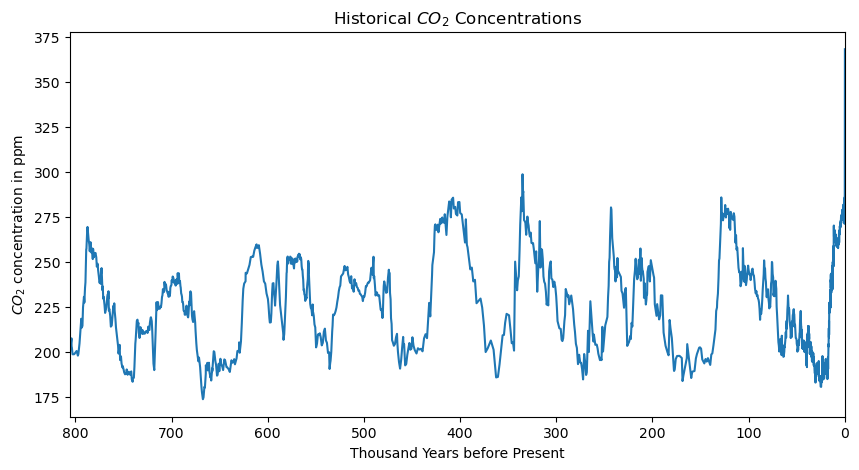

In [ ]:
#Plot co2_ppm versus age_ka
plt.figure(figsize=(10,5))
plt.plot(ice_core_co2['age_ka'], ice_core_co2['co2_ppm'], label='$CO_2$ Concentration')
plt.xlim(ice_core_co2['age_ka'].max(), ice_core_co2['age_ka'].min())
plt.title('Historical $CO_2$ Concentrations')
plt.xlabel('Thousand Years before Present')
plt.ylabel('$CO_2$ concentration in ppm')
plt.show()

Because this is real observational data, they are unevenly sampled in time. To analyze these data, we need to have an evenly spaced timeseries. We can use the scipy interpolation capabilities to do so using `interp1d`.

In [ ]:
interp1d?

Init signature:
interp1d(
    x,
    y,
    kind='linear',
    axis=-1,
    copy=True,
    bounds_error=None,
    fill_value=nan,
    assume_sorted=False,
)
Docstring:     
Interpolate a 1-D function (legacy).

.. legacy:: class

    For a guide to the intended replacements for `interp1d` see
    :ref:`tutorial-interpolate_1Dsection`.

`x` and `y` are arrays of values used to approximate some function f:
``y = f(x)``. This class returns a function whose call method uses
interpolation to find the value of new points.

Parameters
----------
x : (npoints, ) array_like
    A 1-D array of real values.
y : (..., npoints, ...) array_like
    An N-D array of real values. The length of `y` along the interpolation
    axis must be equal to the length of `x`. Use the ``axis`` parameter
    to select correct axis. Unlike other interpolators, the default
    interpolation axis is the last axis of `y`.
kind : str or int, optional
    Specifies the kind of interpolation as a string or as an integer
 

Here is an simple example from the scipy documentation:

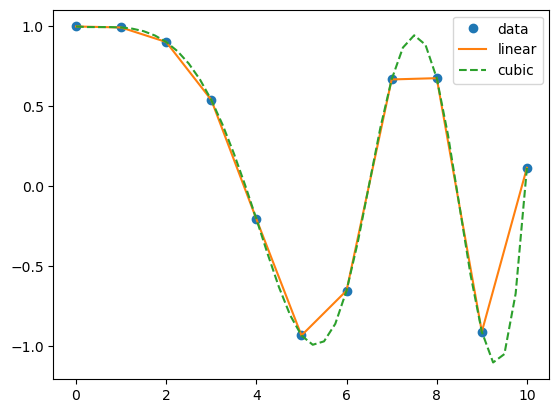

In [ ]:
#Create an example function
x = np.linspace(0, 10, 11,True) #The "True" argument includes the upper limit in the series
y = np.cos(-x**2/9.0)

#Create the interpolation functions
f = interp1d(x, y, kind='linear') #linear interpolation function
f2 = interp1d(x, y, kind='cubic') #cublic spline interpolation function

#Create new x-values
xnew = np.linspace(0, 10, 41, True) #The "True" argument includes the upper limit in the series

#Create new y values with interpolation functions
ynew=f(xnew)
ynew2=f2(xnew)

#Plot original x,y and xnew,ynew
plt.plot(x, y, 'o')
plt.plot(xnew, ynew, '-')
plt.plot(xnew, ynew2, '--')
plt.legend(['data', 'linear', 'cubic'], loc='best')
plt.show()

We can apply such an interpolation to the ice core data and resample it a evenly spaced 1 kyr intervals:

<font color=goldenrod>**Code for you to write**</font>

Interpolate the series `ice_core_co2['age_ka']` and `ice_core_co2['co2_ppm']` every 1 ka between 0 and 800 ka
1. use `interp1d` to create the interpolation function and use a `linear` interpolation
2. create a timeseries between 0 and 800 sampled every **1 ka**
3. apply your interpolation function to create the interpolated co2 data
4. Create a plot of the original ice core date (plotted as points) and add a line of the interpolated co2 data on top (plotted as a line), add labels to each plot 
5. Add axis labels, a title, a legend, and plot the x-axis from 800 ka to the present day

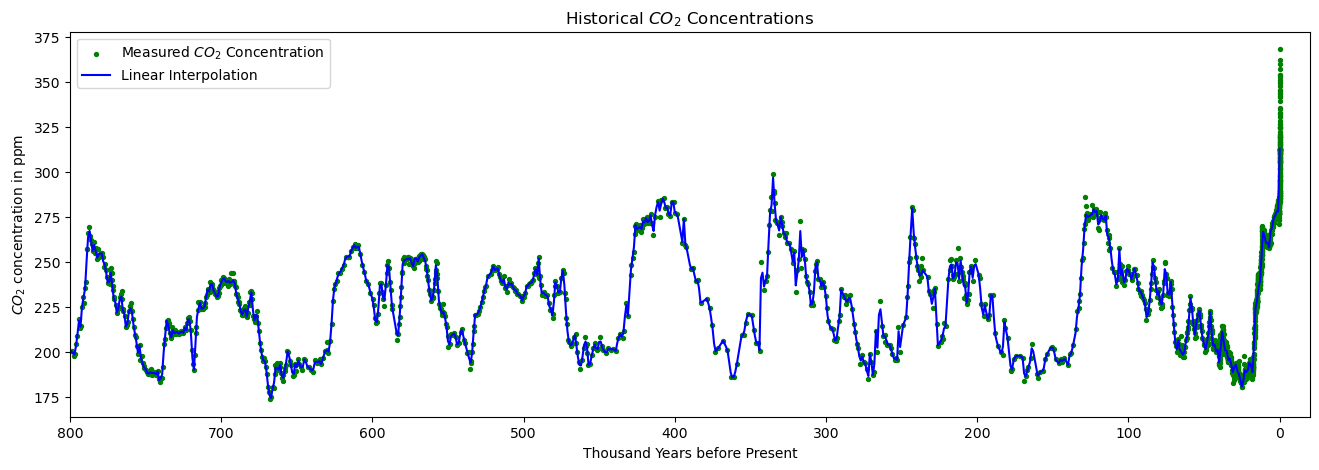

In [ ]:
#Create a linear interpolation function
f = interp1d(ice_core_co2['age_ka'], ice_core_co2['co2_ppm'], kind='linear')

#Create a time series with 1 kyr intervals
xnew=np.linspace(0,800,801,True)

#Create new y values with interpolation functions
co2_interp =f(xnew)

#Plot co2_ppm and co2_interp through time
plt.figure(figsize=(16,5))
plt.scatter(ice_core_co2['age_ka'], ice_core_co2['co2_ppm'], label='Measured $CO_2$ Concentration', color='green', s=8)
plt.plot(xnew, co2_interp, label='Linear Interpolation', color='blue')
plt.xlim(xnew.max(), xnew.min()-20)
plt.title('Historical $CO_2$ Concentrations')
plt.xlabel('Thousand Years before Present')
plt.ylabel('$CO_2$ concentration in ppm')
plt.legend()
plt.show()


In [ ]:
help(np.linspace)

Help on _ArrayFunctionDispatcher in module numpy:

linspace(
    start,
    stop,
    num=50,
    endpoint=True,
    retstep=False,
    dtype=None,
    axis=0,
    *,
    device=None
)
    Return evenly spaced numbers over a specified interval.

    Returns `num` evenly spaced samples, calculated over the
    interval [`start`, `stop`].

    The endpoint of the interval can optionally be excluded.

    .. versionchanged:: 1.20.0
        Values are rounded towards ``-inf`` instead of ``0`` when an
        integer ``dtype`` is specified. The old behavior can
        still be obtained with ``np.linspace(start, stop, num).astype(int)``

    Parameters
    ----------
    start : array_like
        The starting value of the sequence.
    stop : array_like
        The end value of the sequence, unless `endpoint` is set to False.
        In that case, the sequence consists of all but the last of ``num + 1``
        evenly spaced samples, so that `stop` is excluded.  Note that the step
        

Now let's plot the CO$_2$ and the insolation data above each other.

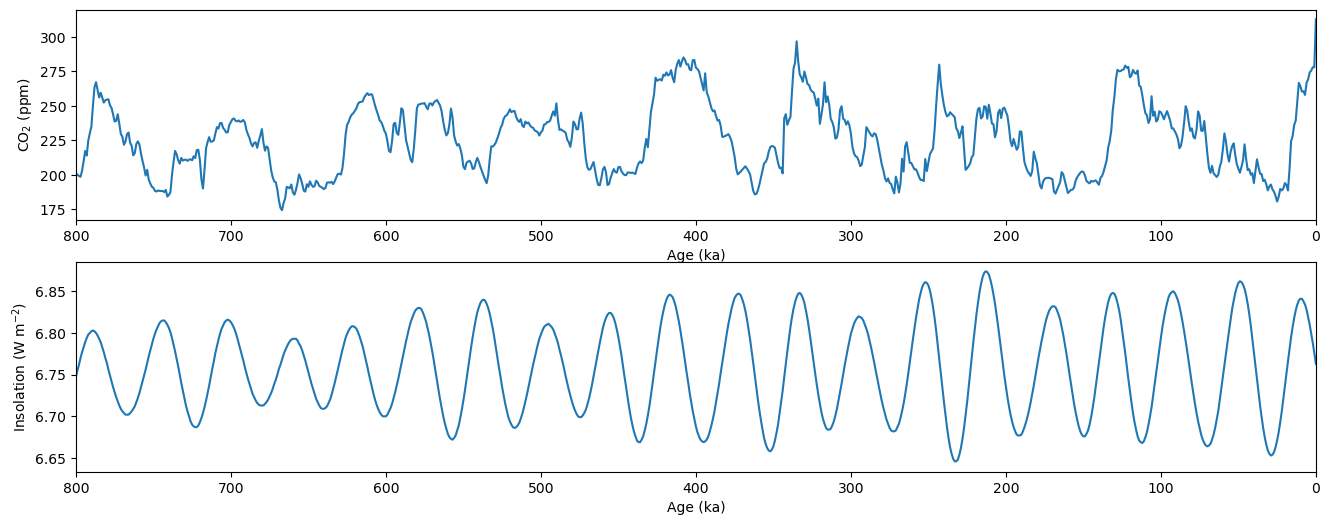

In [ ]:
plt.figure(figsize=(16,6))

plt.subplot(2,1,1)
plt.plot(xnew, co2_interp, '-')
plt.xlim(800,0)
plt.xlabel('Age (ka)')
plt.ylabel('CO$_2$ (ppm)')

plt.subplot(2,1,2)
plt.plot(insolation['Age (ka)'],insolation['Insolation (W/m^2)'])
plt.xlim(800,0)
plt.ylabel('Insolation (W m$^{-2}$)')
plt.xlabel('Age (ka)')
plt.show()

It's difficult to see any relationship when plotted as time series like this.

## What is the dominant signal in the ice sheet CO$_2$ data?

<font color=goldenrod>**Code for you to write**</font>
- Take the same approach above and use the `signal.periodogram()` function to calculate the power spectral density of the interpolated $\text{CO}_2$ data, `co2_interp`.
- Remember to pass the `fs` argument, where `fs` is our interpolation interval, which we set as 1 ka, so `fs=1` 

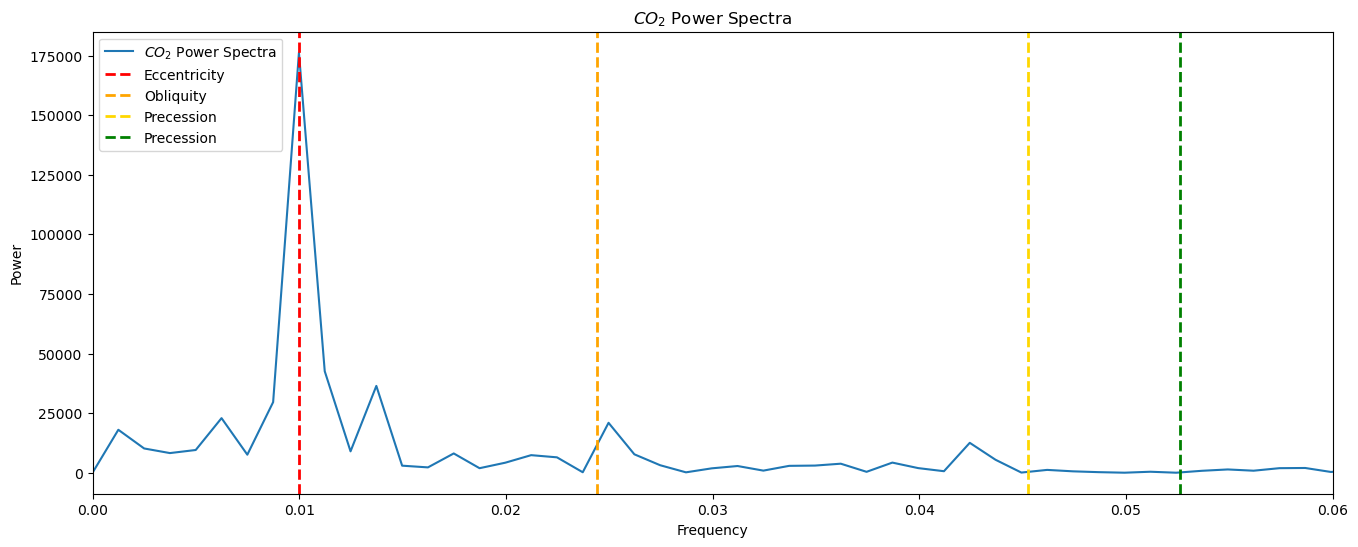

In [ ]:
#Calculate and plot the power as a function of frequency for co2_interp
co2_freqs,co2_power = signal.periodogram(co2_interp, fs=1)

#Plot power (y) as a function of frequency (x)
# plt.semilogy(insolation_freqs,insolation_power,label='Insolation power spectra')
plt.figure(figsize=(16,6))
plt.plot(co2_freqs, co2_power, label='$CO_2$ Power Spectra')
plt.title('$CO_2$ Power Spectra')
plt.xlabel('Frequency')
plt.ylabel('Power')
plt.axvline(x=eccentricity_frequency,color='red',label='Eccentricity',linewidth=2,linestyle='--') 
plt.axvline(x=obliquity_frequency,color='orange',label='Obliquity',linewidth=2,linestyle='--')
plt.axvline(x=precession_frequency_1,color='gold',label='Precession',linewidth=2,linestyle='--') 
plt.axvline(x=precession_frequency_2,color='green',label='Precession',linewidth=2,linestyle='--') 
plt.xlim(0.0,0.06)
plt.legend()
plt.show()

Now lets plot the CO$_2$ spectrum and compare it with the orbital parameters, like before.

In [ ]:
plt.semilogy(co2_freqs,co2_power,label='$\text{CO}_2$ power spectra',linewidth=2)
plt.axvline(x=eccentricity_frequency,color='red',label='Eccentricity',linewidth=2,linestyle='--') 
plt.axvline(x=obliquity_frequency,color='orange',label='Obliquity',linewidth=2,linestyle='--')
plt.axvline(x=precession_frequency_1,color='gold',label='Precession',linewidth=2,linestyle='--') 
plt.axvline(x=precession_frequency_2,color='green',label='Precession',linewidth=2,linestyle='--') 
plt.title('CO$_2$ power spectra, log plot')
plt.xlim(.001,.06)
plt.xlabel('Frequency')
plt.ylabel('Power') 
plt.legend()
plt.show()

NameError: name 'co2_freqs' is not defined

<font color=red>**Discussion question:**</font> What is the dominant signal in the 65ºN insolation curve and how does it compare to dominant period in the ice sheet CO$_2$ data?

## Longer timescale paleoclimate records

The ice core record is a very impressive one, but unfortunately, it only goes back ~800,000 years. While these seems like a long time, it is only 0.02% of the history of the Earth.

One way that we can go further back with a paleoclimate record is using marine fossils such as formainifera. Foraminifera are made of calcium carbonate: CaCO$_3$

The oxygen isotopes ($^{16}$O vs $^{18}$O) in the CaCO$_3$ forms a record of both of temperature and ice volume. $\delta^{18}$O is a way to express the ratio between $^{16}$O and $^{18}$O. 

$$\delta ^{18}O={\Biggl (}{\frac  {{\bigl (}{\frac  {^{{18}}O}{^{{16}}O}}{\bigr )}_{{sample}}}{{\bigl (}{\frac  {^{{18}}O}{^{{16}}O}}{\bigr )}_{{standard}}}}-1{\Biggr )}\times 1000\ ^{{o}}\!/\!_{{oo}}$$

When water is warm $\delta ^{18}$O is low and when water is cold $\delta ^{18}$O is high. There is a similar relationship with ice volume: when there is less ice the $\delta ^{18}$O of water is lower and there is more ice is cold $\delta ^{18}$O of water is higher which ends up contributing to the value of the fossil foraminifera.

So higher $\delta^{18}$O values are associated with a colder planet and lower $\delta^{18}$O values with a warmer planet.

A compilation of these data was published by Lisecki and Raymo (2005, http://dx.doi.org/10.1029/2004PA001071) called the LR04 stack.  This is a stack of 58 records of oxygen isotopic variations, several of which were independently dated using magnetostratigraphy, from all over the world's oceans.   

Let's import the data and take a look at the record: 

<font color=goldenrod>**Code for you to write**</font>

Read in the csv file from `./data/LR04stack.csv` into the dataframe `LR04_d18O`:
1. There is no header and you don't need to specify the separator
2. Display the dataframe to the screen using the usual tools

In [ ]:
#Read in and display the delta 18O data
LR04_d18O = pd.read_csv('data/LR04stack.csv')
LR04_d18O.head()

,Age (ka),d18O,uncertainty
0,0.0,3.23,0.03
1,1.0,3.23,0.04
2,2.0,3.18,0.03
3,3.0,3.29,0.03
4,4.0,3.30,0.03


Make a plot using `plt.plot` of the $\delta ^{18}$O data.

<font color=goldenrod>**Code for you to write**</font>
1. Plot `Age (ka)`versus `d18O`
2. Use `plt.xlim()` to make it so that time is limited and goes from 5320 ka to 0 ka
3. Add axis labels and a title.

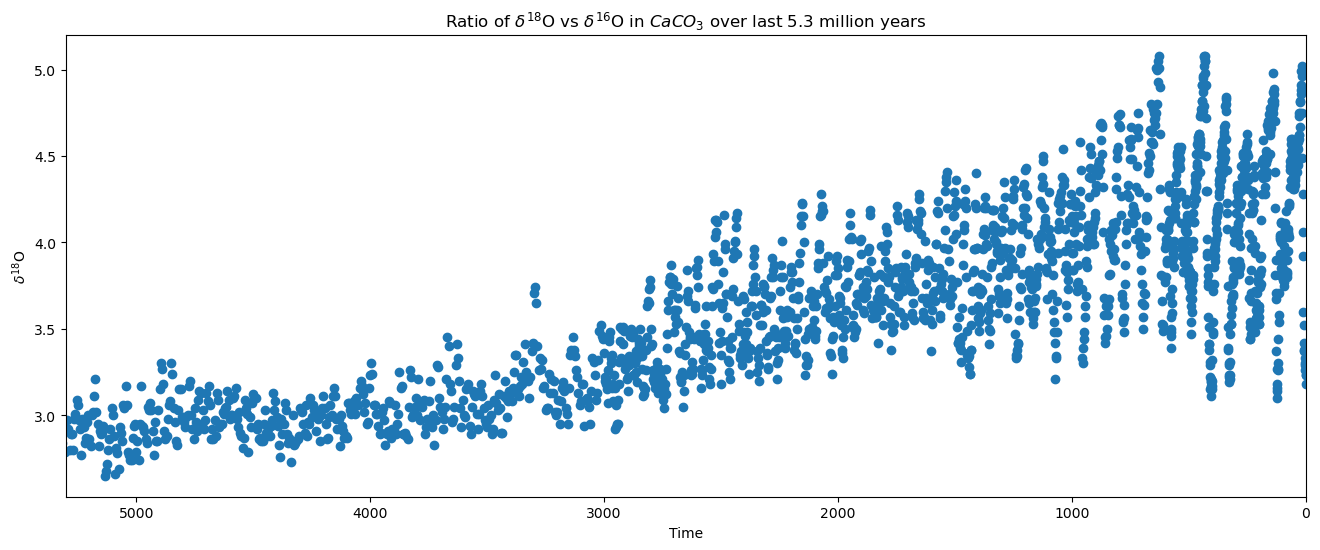

In [ ]:
#Plot d18O through time
plt.figure(figsize=(16,6))
plt.scatter(LR04_d18O['Age (ka)'],LR04_d18O['d18O'], label='Ratio of $\\delta^18$')
plt.title('Ratio of $\\delta ^{18}$O vs $\\delta ^{16}$O in $CaCO_3$ over last 5.3 million years')
plt.xlabel('Time')
plt.ylabel('$\\delta ^{18}$O')
plt.xlim(5300,0)
plt.show()

Let's interpolate the data and assign it to a new dataframe

In [ ]:
#Interpolate the data
d18O_interp = interp1d(LR04_d18O['Age (ka)'], LR04_d18O['d18O'], kind='linear')

#Crate the uniform time series
age_uniform = np.linspace(0, 5320,5321,True)

#Interpolate the d18O values to the uniform time series
d18O_interp = d18O_interp(age_uniform)

#Create a new interpolated dataframe
interpolated_dataframe={'Age (ka)': age_uniform, 'd18O': d18O_interp}
LR04_d18O_interp = pd.DataFrame(data=interpolated_dataframe)

Now we can just look at the last 1000 years, like before

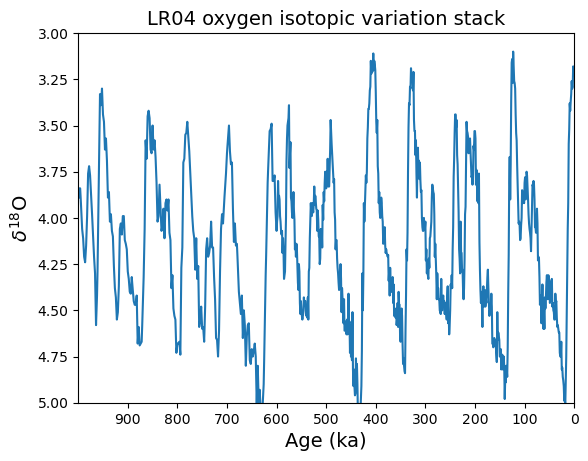

In [ ]:
d18O_1Ma=LR04_d18O_interp[LR04_d18O_interp['Age (ka)']<1000] # filter data for last 1Ma

plt.plot(d18O_1Ma['Age (ka)'],d18O_1Ma['d18O'])
plt.title('LR04 oxygen isotopic variation stack', fontsize=14)
plt.xlabel('Age (ka)', fontsize=14)
plt.ylabel('$\\delta ^{18}$O', fontsize=14)
plt.ylim(5,3)
plt.xlim(1000,0)
plt.xticks(range(0,1000,100))
plt.show()

We can compare this with the CO$_2$ time series.

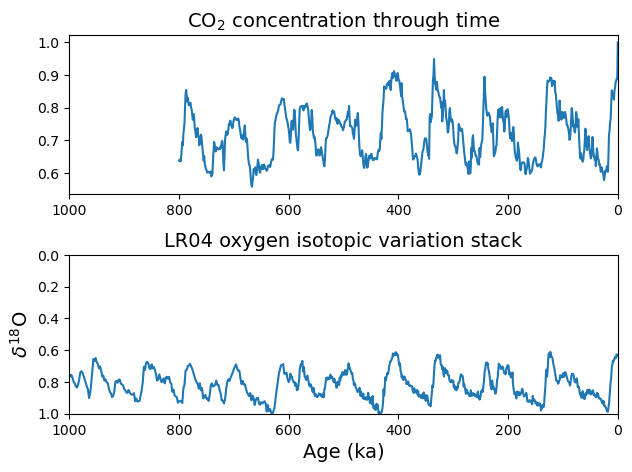

In [ ]:
plt.subplot(2,1,1)
plt.plot(xnew, co2_interp/np.max(co2_interp))
plt.title('CO$_2$ concentration through time', fontsize=14)
plt.xlim(1000,0)

plt.subplot(2,1,2)
plt.plot(d18O_1Ma['Age (ka)'],d18O_1Ma['d18O']/np.max(d18O_1Ma['d18O']))
plt.title('LR04 oxygen isotopic variation stack', fontsize=14)
plt.xlabel('Age (ka)', fontsize=14)
plt.ylabel('$\\delta ^{18}$O', fontsize=14)
plt.tight_layout(pad=1.0)
plt.ylim(1,0)
plt.xlim(1000,0)
plt.show()

Let's do the same signal analysis in order to analyze the power spectra:

<font color=goldenrod>**Code for you to write**</font>
- Calculate the frequencies and powers for the interpolated d18O dataframe.
- Plot the frequencies and powers on a logarithmic y-axis using `semilogy`
- Plot the orbital parameter frequncies as vertical lines like before.

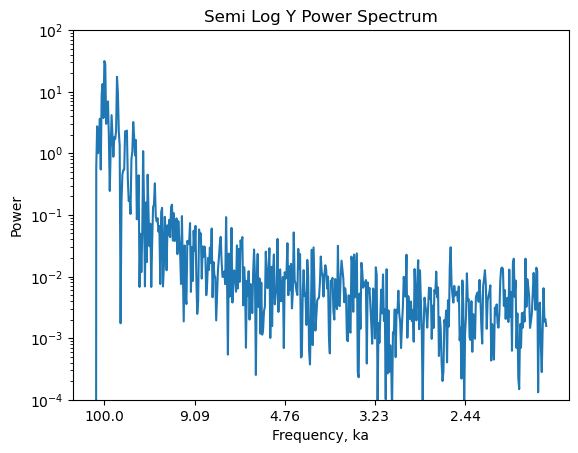

In [ ]:
frequency_d18O, power_d18O = signal.periodogram(d18O_1Ma['d18O'], 1)
plt.semilogy(frequency_d18O, power_d18O)
plt.title('Semi Log Y Power Spectrum')
plt.ylim(10e-5,10e1)
plt.xlabel('Frequency, ka')
plt.ylabel('Power') 
xticks = np.arange(0.01,0.5,.1)
xlabels = 1/xticks
plt.xticks(xticks, np.round(xlabels,2))


plt.show()

<font color=red>**Question**</font>

Interpret the data and match it with the summary below

### Summary

- $\delta ^{18}$O records **palaeotemperature**
- $\text{CO}_2$ data shows the **response to climate forcings** (up until the present day when things have changed)
- Solar insolation (controlled by the orbital paramters) **influences the amount of energy arriving on Earth** in the northern hemisphere
- **Both the $\delta ^{18}$O and CO$_2$ have the same periodicities as the orbital parameters (Milankovitch cycles), showing that palaeoclimate is controlled by the Earth's orbit, and enhanced by feedbacks such as CO$_2$ release.**
- Milankovitch cycles can be observed in the geological record
<img src="./figures/Milankovitch-cycles-in-an-outcrop-of-Permian-marine-carbonates.png" width = 1200>
Visual identification of Milankovitch cycles in an outcrop of Permian marine carbonates from the Dalong Formation, China (modified from Wu et al. 2013). Note the groups of layers identified as a product of precession forming cycles of 100 kyr (short eccentricity) regrouped in cycles of 405 kyr (long eccentricity). Source: modified from Wu et al. (2013).

### Turn in this notebook

Save your completed notebook, print the file to PDF, and upload the PDF on Blackboard.

In [ ]:
https://clima.github.io/Insolation.jl/dev/


First, let's watch a video about what controls temperatures on Earth, and how this relates to atmospheric $\text{CO}_2$.

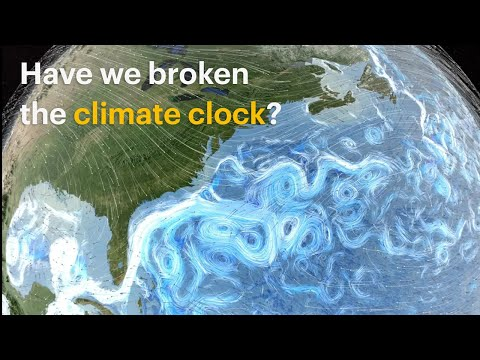

In [ ]:
from IPython.display import YouTubeVideo
YouTubeVideo('qKY7AN3tB_s', width="1000", height="500")